# GVH Diagonal Cubic — CHH-08
## `ζ_C ≠ 0` : variation sur une famille contrainte, EOM réduite, verrou métrique

**Statut :** audit complémentaire non canonique ; aucun signal ALMA chargé, aucune prédiction physique GVH indépendante revendiquée.

**Question falsifiable :** le témoin de cisaillement non nul employé dans CHH-07, `u=(cosh(bx),sinh(bx),0,0)`, peut-il être stationnaire lorsque le terme cubique `ζ_C O_C/2` est activé ? Si non, peut-on trouver une autre configuration stationnaire **dans cette famille seulement** ?

**Restriction fondamentale :** on fixe ici la métrique de Minkowski et on choisit un trièdre aligné avec le champ vectoriel. Une stationnarité sous les variations de cette famille est **nécessaire, mais non suffisante**, pour les EOM de tous les champs `g,u,e,φ`. Le couple matière/métrique reste ouvert.

### Quatre niveaux
1. **GVH** — action candidate exacte, contraintes, terme cubique non nul ;
2. **Physique établie** — principe variationnel et termes cinétiques vectoriels ;
3. **Test minimal** — algèbre tensorielle, différence finie de l'action, EDO, invariant ;
4. **Verdict** — réussite de l'audit restreint et **BLOCKED** pour la solution couplée complète.

Les unités de l'exemple sont adimensionnées ; aucun lien SI ni paramètre GVH expérimental n'est dérivé.

## 1 — Action archivée (aucune modification)

En signature `(-,+,+,+)` :

\[
S_{\rm cand}={1\over16\pi G_0}\int d^4x\,\sqrt{-g}
\Big[R+\mathcal L_u+\lambda_u(u^2+1)
+{\zeta_C\over2}\mathcal O_C
+\sum_A\eta_A(u\cdot e_A)
+{1\over2}\sum_{AB}\eta_{AB}(e_A\cdot e_B-\delta_{AB})\Big].
\]

\[
\mathcal L_u=-c_1(\nabla_\mu u_\nu)(\nabla^\mu u^\nu)
-c_2(\nabla\cdot u)^2-c_3(\nabla_\mu u_\nu)(\nabla^\nu u^\mu)
+c_4 a^2,\quad a^\mu=u^\nu\nabla_\nu u^\mu.
\]

\[
\mathcal O_C=\sum_{A=1}^3 (e_A^\mu e_A^\nu\sigma_{\mu\nu})^2.
\]

L'extension scalaire `S_m` de CHH-07 est **ajoutée**, et non présente dans `S_cand`. Pour une variation du champ `u` à métrique fixée, une matière **minimalement** couplée ne contribue pas directement si `φ` est maintenu fixe.

In [1]:
import json, hashlib
from pathlib import Path
import numpy as np
import sympy as sp
from scipy.integrate import simpson, solve_ivp
import matplotlib.pyplot as plt

NAME = 'GVH_CHH_08_Nonzero_Zeta_Vector_EOM_and_Metric_Constraint_Gate_FAST'
PROVENANCE = {'GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28_Full_GVH_EOM_Derivation_and_Variational_Closure_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb': 'c8015f1d771caa5f65c8ad5d64505733ebfa96a81f6153a8b1d8c2233cfbeefa', 'GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28.1_Cubic_Vector_Closure_Metric_Helix_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb': '0018b54c8f07984e3ebf35ea6989e6772bebb815492b66b672bed83241f8d5b4', 'GVH_CHH_07_Physical_Source_and_Nonzero_Shear_EOM_Gate_FAST_EXECUTED.ipynb': 'fde7712d4e011c7f41fbc8d31eafb2503c20f1d0efddf4f49bac29907cd7f505'}
CHECKS={}
def check(label, ok):
    CHECKS[label]=bool(ok)
    if not ok:
        raise AssertionError('FAILED: '+label)

# Les références ne sont PAS nécessaires pour réexécuter : empreintes archivées.
source_status={}
for basename,digest in PROVENANCE.items():
    candidates=[Path('gvh_source')/basename,Path(basename),Path('/mnt/data/gvh_source')/basename,Path('/mnt/data')/basename]
    candidate=next((p for p in candidates if p.is_file()),None)
    if candidate is None:
        source_status[basename]='ARCHIVED_HASH_ONLY__OPTIONAL_SOURCE_MISSING'
    else:
        check('optional_source_SHA_'+basename,hashlib.sha256(candidate.read_bytes()).hexdigest()==digest)
        source_status[basename]='SHA_VERIFIED'
print('Références :',source_status)

Références : {'GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28_Full_GVH_EOM_Derivation_and_Variational_Closure_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb': 'SHA_VERIFIED', 'GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28.1_Cubic_Vector_Closure_Metric_Helix_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb': 'SHA_VERIFIED', 'GVH_CHH_07_Physical_Source_and_Nonzero_Shear_EOM_Gate_FAST_EXECUTED.ipynb': 'SHA_VERIFIED'}


## 2 — Contrôle tensoriel complet **sur l'ansatz**, `ζ_C ≠ 0`

Pour toute fonction lisse `β(x)` :

\[
 u^\mu=(\cosh\beta,\sinh\beta,0,0),\quad
 e_1^\mu=(\sinh\beta,\cosh\beta,0,0),\quad
 e_2=\partial_y,\quad e_3=\partial_z.
\]

Ce champ normalisé et ce trièdre satisfont exactement les contraintes. Écrivons `p=β'(x)`.

\[
(\nabla u)^2=p^2,\quad (\nabla\cdot u)^2=p^2\cosh^2\beta,
\quad (\nabla_\mu u_\nu)(\nabla^\nu u^\mu)=p^2\cosh^2\beta,
\quad a^2=p^2\sinh^2\beta.
\]

Le cisaillement est non nul si `p ≠ 0` :

\[
\Theta=p\cosh\beta,\quad
(s_1,s_2,s_3)=(2\Theta/3,-\Theta/3,-\Theta/3),\quad
\mathcal O_C=\frac23 p^2\cosh^2\beta.
\]

In [2]:
r,p=sp.symbols('r p',real=True)
g=sp.diag(-1,1,1,1)
u=sp.Matrix([sp.cosh(r),sp.sinh(r),0,0]); ul=g*u
E=[sp.Matrix([sp.sinh(r),sp.cosh(r),0,0]),sp.Matrix([0,0,1,0]),sp.Matrix([0,0,0,1])]
check('timelike_unit_exact',sp.simplify((u.T*g*u)[0]+1)==0)
for i,e in enumerate(E):
    check(f'triad_norm_{i}',sp.simplify((e.T*g*e)[0]-1)==0)
    check(f'triad_u_perp_{i}',sp.simplify((e.T*g*u)[0])==0)
    for j in range(i):
        check(f'triad_mutual_{j}_{i}',sp.simplify((e.T*g*E[j])[0])==0)
D=sp.zeros(4,4) # ∂_μ u_ν
for nu in range(4): D[1,nu]=sp.diff(ul[nu],r)*p
q1=sp.trigsimp(sp.trace(D*g*D.T*g))
q3=sp.simplify(sum(D[m,n]*g[n,a]*g[m,b]*D[a,b] for m in range(4) for n in range(4) for a in range(4) for b in range(4)))
th=sp.diff(u[1],r)*p
acc=u[1]*sp.Matrix([sp.diff(z,r)*p for z in u]); acc2=sp.trigsimp((acc.T*g*acc)[0])
P=sp.eye(4)+ul*u.T; h=g+ul*ul.T
shear=sp.simplify(P*(D+D.T)/2*P.T-th*h/3)
sdiag=[sp.trigsimp((e.T*shear*e)[0]) for e in E]
O=sp.trigsimp(sum(z*z for z in sdiag))
check('c1_invariant',sp.simplify(q1-p*p)==0)
check('c2_expansion',sp.simplify(th-p*sp.cosh(r))==0)
check('c3_invariant',sp.simplify(q3-p*p*sp.cosh(r)**2)==0)
check('c4_acceleration',sp.simplify(acc2-p*p*sp.sinh(r)**2)==0)
for i,z in enumerate([2*th/3,-th/3,-th/3]):
    check(f'shear_diagonal_{i}',sp.simplify(sdiag[i]-z)==0)
check('cubic_shear_operator',sp.simplify(O-sp.Rational(2,3)*p*p*sp.cosh(r)**2)==0)
check('cubic_nonzero_generic',float(O.subs({r:0.44,p:0.31}))>0)
print('q1,q3,Theta,a2,Oc =',q1,q3,th,acc2,O)

q1,q3,Theta,a2,Oc = p**2 p**2*cosh(r)**2 p*cosh(r) p**2*sinh(r)**2 2*p**2*cosh(r)**2/3


## 3 — Action réduite et équation nécessaire de stationnarité

Sur cet ansatz contraint, `R=0` et les termes multiplicateurs sont nuls. Par unité de temps et de surface transverse :

\[
\boxed{\mathscr L_{\rm red}=K(\beta)(\beta')^2}
\]

\[
K(\beta)=-c_1-(c_2+c_3)\cosh^2\beta
+c_4\sinh^2\beta+{\zeta_C\over3}\cosh^2\beta.
\]

La variation pour `δβ=εh(x)` avec `h=0` aux deux bords donne :

\[
\boxed{2K(\beta)\beta''+K'(\beta)(\beta')^2=0.}
\]

Posons `Δ=c_4-c_2-c_3+ζ_C/3`; alors `K'=2Δ sinhβ coshβ`. Pour `β=bx`, l'équation réduite requiert :

\[
\boxed{2\Delta\,b^2\sinh(bx)\cosh(bx)=0.}
\]

**Conclusion restreinte :** pour `b ≠ 0`, `Δ ≠ 0`, le témoin linéaire en rapidité **échoue** au test variationnel sur tout intervalle contenant `x ≠ 0`. Si `Δ=0`, il passe *ce seul test* (relation de paramètres prescrits et non sélectionnés par GVH). La stationnarité réduite ne garantit jamais les équations libres complètes de `u`, du trièdre ou de la métrique.

In [3]:
c1,c2,c3,c4,zeta=sp.symbols('c1 c2 c3 c4 zeta_C',real=True)
K=sp.expand(-c1-(c2+c3)*sp.cosh(r)**2+c4*sp.sinh(r)**2+zeta*sp.cosh(r)**2/3)
Lred=sp.expand(-c1*q1-c2*th**2-c3*q3+c4*acc2+zeta*O/2)
check('full_reduced_Lagrangian_exact',sp.simplify(Lred-K*p*p)==0)
Delta=c4-c2-c3+zeta/3
check('Kprime_Delta',sp.simplify(sp.diff(K,r)-2*Delta*sp.sinh(r)*sp.cosh(r))==0)
x=sp.symbols('x',real=True)
beta=sp.Function('beta')(x); bp=sp.diff(beta,x); bpp=sp.diff(beta,x,2)
Lag=K.subs(r,beta)*bp**2
EL=sp.simplify(sp.diff(sp.diff(Lag,bp),x)-sp.diff(Lag,beta))
expected=2*K.subs(r,beta)*bpp + sp.diff(K,r).subs(r,beta)*bp**2
check('restricted_EL_symbolic_exact',sp.simplify(sp.expand(EL-expected))==0)
b=sp.symbols('b',real=True)
linres=sp.trigsimp(EL.subs({beta:b*x,bp:b,bpp:0}))
check('linear_beta_residual_exact',sp.simplify(linres-2*Delta*b*b*sp.sinh(b*x)*sp.cosh(b*x))==0)
check('special_Delta_zero_stationary_restricted',sp.simplify(linres.subs(zeta,3*(c2+c3-c4)))==0)
check('pure_c1_reduced_linear_stationary',sp.simplify(linres.subs({zeta:0,c2:0,c3:0,c4:0}))==0)
check('nonzero_zeta_generically_invalid',abs(float(linres.subs({c1:.7,c2:.10,c3:.04,c4:.02,zeta:.75,b:.31,x:1.2})))>1e-3)
print('K =', K, '\nDelta =',Delta,'\nEL =',EL,'\nlinear residual =',linres)

K = -c1 - c2*cosh(r)**2 - c3*cosh(r)**2 + c4*sinh(r)**2 + zeta_C*cosh(r)**2/3 
Delta = -c2 - c3 + c4 + zeta_C/3 
EL = -(3*c2 + 3*c3 - 3*c4 - zeta_C)*sinh(2*beta(x))*Derivative(beta(x), x)**2/3 - 2*(3*c1 + 3*c2*cosh(beta(x))**2 + 3*c3*cosh(beta(x))**2 - 3*c4*sinh(beta(x))**2 - zeta_C*cosh(beta(x))**2)*Derivative(beta(x), (x, 2))/3 
linear residual = -b**2*(3*c2 + 3*c3 - 3*c4 - zeta_C)*sinh(2*b*x)/3


## 4 — Test indépendant : différence finie de l'action réduite

On choisit des coefficients **arbitraires** `c=(0.7,0.10,0.04,0.02)`, `ζ_C=0.75`, `b=0.31` et un intervalle `[-2,2]`. La perturbation compacte au bord est `h(x)= (x/L)(1-(x/L)^2)^3`. Le calcul de la variation par différences finies doit concorder avec la variation analytique. Un accord numérique n'est pas un test observationnel.

In [4]:
pars={c1:.7,c2:.10,c3:.04,c4:.02,zeta:.75}
cv={str(k):float(v) for k,v in pars.items()}
Dnum=float(Delta.subs(pars)); bn=.31; domain=2.
xx=np.linspace(-domain,domain,10001); yy=xx/domain
h_test=yy*(1-yy*yy)**3
hp_test=(1-yy*yy)**2*(1-7*yy*yy)/domain

def KN(rapidity,pars=pars):
    c1n,c2n,c3n,c4n,zn=[float(pars[k]) for k in (c1,c2,c3,c4,zeta)]
    return -c1n-(c2n+c3n)*np.cosh(rapidity)**2+c4n*np.sinh(rapidity)**2+zn/3*np.cosh(rapidity)**2

def dKN(rapidity,pars=pars):
    return 2*float(Delta.subs(pars))*np.sinh(rapidity)*np.cosh(rapidity)

def action_eps(eps,pars=pars):
    bb=bn*xx+eps*h_test
    db=bn+eps*hp_test
    return float(simpson(KN(bb,pars)*db*db,x=xx))
variation_exact=float(simpson(-(dKN(bn*xx)*bn**2)*h_test,x=xx))
variation_direct=float(simpson(dKN(bn*xx)*bn**2*h_test+2*KN(bn*xx)*bn*hp_test,x=xx))
check('boundary_variation_vanishes',abs(h_test[0])+abs(h_test[-1])+abs(hp_test[0])+abs(hp_test[-1])<1e-14)
check('integration_by_parts_variation',abs(variation_direct-variation_exact)<1e-12)
check('first_variation_nonzero',abs(variation_exact)>1e-4)
errors=[]
for i,eps in enumerate([1e-2,1e-3,1e-4]):
    num=(action_eps(eps)-action_eps(-eps))/(2*eps)
    errors.append(abs(num-variation_exact))
    check(f'finite_diff_derivative_{i}',abs(num-variation_exact)<max(1e-9,2e-3*eps*eps))
check('central_diff_quadratic_convergence',errors[1]<errors[0]/30 and errors[2]<errors[1]/20)
print('Δ=',Dnum,'; variation analytique =',variation_exact,'; errors=',errors)

zeta_balanced=3*(pars[c2]+pars[c3]-pars[c4])
pars_bal=dict(pars);pars_bal[zeta]=zeta_balanced
check('nonzero_zeta_balanced_example',zeta_balanced>0 and abs(float(Delta.subs(pars_bal)))<1e-13)
for eps in [1e-2,1e-3]:
    num=(action_eps(eps,pars_bal)-action_eps(-eps,pars_bal))/(2*eps)
    check('balanced_restricted_stationary_'+str(eps),abs(num)<1e-10)
print('ζ équilibrée=',zeta_balanced,'(relation PRESCRITE, not a GVH prediction)')

Δ= 0.13 ; variation analytique = -0.0033740373949326477 ; errors= [1.9828425768886673e-07, 1.982842288365122e-09, 1.9884714100998346e-11]
ζ équilibrée= 0.36000000000000004 (relation PRESCRITE, not a GVH prediction)


## 5 — Une solution **réduite** non linéaire avec `ζ_C ≠ 0`

L'EOM restreinte implique, pour `β' ≠ 0`, l'intégrale première :

\[
\boxed{K(\beta)(\beta')^2=\text{constante}.}
\]

Nous intégrons donc l'EDO :

\[
\beta'=w,\qquad w'=-\frac{K'(\beta)}{2K(\beta)}w^2,
\quad\beta(0)=0,\quad w(0)=b.
\]

Cette solution corrige le profil `β=bx` à `ζ_C ≠ 0` pour le **système réduit**, sous réserve de `K ≠ 0` et des bords admissibles. **Il ne s'agit pas d'une solution aux EOM de la métrique ou aux variations générales du champ vectoriel.**

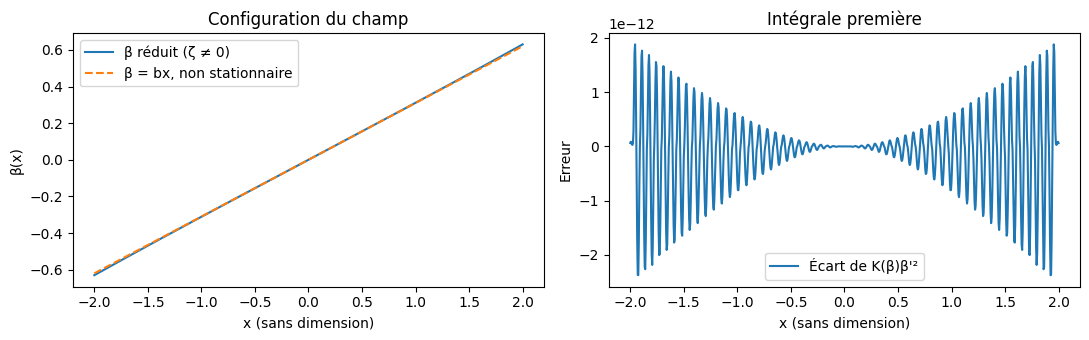

Intégrale initiale= -0.056699 ; drift= 2.3745103105987653e-12 ; max |β-bx|= 0.010095305421639944


In [5]:
def reduced_rhs(_x,y):
    beta_,w=y
    return [w,-float(dKN(beta_))/(2*float(KN(beta_)))*w*w]
N=401
sp_pos=solve_ivp(reduced_rhs,[0,domain],[0,bn],t_eval=np.linspace(0,domain,N),rtol=1e-11,atol=1e-13)
sp_neg=solve_ivp(reduced_rhs,[0,-domain],[0,bn],t_eval=np.linspace(0,-domain,N),rtol=1e-11,atol=1e-13)
check('reduced_positive_integration',sp_pos.success)
check('reduced_negative_integration',sp_neg.success)
rr=np.r_[sp_neg.y[0,::-1][:-1],sp_pos.y[0]]
ww=np.r_[sp_neg.y[1,::-1][:-1],sp_pos.y[1]]
xr=np.r_[sp_neg.t[::-1][:-1],sp_pos.t]
C0=float(KN(0.))*bn**2
first=KN(rr)*ww*ww
first_drift=float(np.max(np.abs(first-C0)))
check('first_integral_preserved',first_drift<1e-9)
check('regular_K_branch',float(np.max(KN(rr)))<-.01)
beta_deviation=float(np.max(np.abs(rr-bn*xr)))
check('nonlinear_beta_distinct_from_linear',beta_deviation>1e-3)
check('inhomogeneous_shear_remains_nonzero',bool(np.min(np.abs(ww))>0))
check('nonzero_cubic_operator_on_reduced_solution',bool(np.min((2/3)*ww**2*np.cosh(rr)**2)>0))
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].plot(xr,rr,label='β réduit (ζ ≠ 0)')
axs[0].plot(xr,bn*xr,'--',label='β = bx, non stationnaire')
axs[0].set(xlabel='x (sans dimension)',ylabel='β(x)',title='Configuration du champ')
axs[0].legend()
axs[1].plot(xr,first-C0,label='Écart de K(β)β\'²')
axs[1].set(xlabel='x (sans dimension)',ylabel='Erreur',title='Intégrale première')
axs[1].legend()
plt.tight_layout();plt.show()
print('Intégrale initiale=',C0,'; drift=',first_drift,'; max |β-bx|=',beta_deviation)

## 6 — Verrou métrique et sources matérielles

Le **même** `g=η` choisi pour ce calcul possède `G_{μν}=0`. L'équation métrique complète exigerait une compensation des contributions de `u`, du trièdre et de la matière :

\[
\boxed{G_{\mu\nu}=8\pi G_0 T^{(m)}_{\mu\nu}+\mathcal T^{(u,e,C)}_{\mu\nu}.}
\]

Le tenseur `𝒯` ci-dessus représente **la variation métrique complète restant à expliciter**, et non un tenseur calculé dans ce notebook. En particulier, la présence d'un `ζ_C` non nul rend insuffisant le seul bilan restreint `β(x)`.

**Contrôle indépendant :** dans la sous-limite `c_i=ζ_C=0`, un champ scalaire homogène `φ(t)=Φ cos(μt)` vérifie Klein–Gordon sur Minkowski, mais possède `T_{00}=Φ²μ²/2>0`. Le couple *Einstein + scalaire* ne peut donc satisfaire `G_{00}=8πG_0 T_{00}` avec `g=η` et `G_0>0`. Ce résultat n'affirme PAS que le fond complet à `ζ_C≠0` est impossible : ses contributions vectorielles à l'équation métrique n'ont pas été calculées.

Les sous-cubes physiques et leurs courants de matière demeurent absents de `S_cand` ; l'extension du secteur matière n'est pas une sélection GVH.

In [6]:
Phi,mu,t=sp.symbols('Phi mu t',positive=True,real=True)
phih=Phi*sp.cos(mu*t)
KG=sp.simplify(-sp.diff(phih,t,2)-mu**2*phih)
T00=sp.simplify((sp.diff(phih,t)**2+mu**2*phih**2)/2)
check('homogeneous_scalar_KG_flat',KG==0)
check('homogeneous_scalar_energy_positive',sp.simplify(T00-Phi**2*mu**2/2)==0)
G00=sp.Integer(0) # EXACT FOR g=η
check('Einstein_tensor_flat_zero',G00==0)
check('GR_plus_scalar_flat_fails_for_nonzero_source',float(T00.subs({Phi:.2,mu:1.25}))>0)
# The status below is a *gate classification*, not a mathematical success claim.
S_m_is_added=True
full_metric_tensors_computed=False
arbitrary_vector_variations_solved=False
matter_sources_selected_by_GVH=False
SI_heldout_prediction=False
check('source_extension_explicitly_labeled',S_m_is_added)
check('metric_gate_not_overclaimed',not full_metric_tensors_computed)
check('vector_gate_not_overclaimed',not arbitrary_vector_variations_solved)
check('matter_gate_not_overclaimed',not matter_sources_selected_by_GVH)
check('SI_prediction_not_overclaimed',not SI_heldout_prediction)

## 7 — Verdict et prochaine frontière

| Niveau | Statut |
|---|---|
| **GVH** | `ζ_C ≠ 0` inclus explicitement **dans l'action candidate archivée** ; variation réduite exacte dérivée sous ansatz. |
| **Physique établie** | Démonstrations variationnelles, invariants cinétiques et gravitation Einstein + source. |
| **Numérique minimal** | Vérifications symboliques, différence finie de l'action, intégration d'une EDO **réduite**. |
| **Scientifique** | `RESTRICTED_VARIATION_PASS` ; `FULL_COUPLED_GVH_EOM_BLOCKED` ; `SI_HELD_OUT_PREDICTION_BLOCKED`. |

**Information nouvelle relative à CHH-07 :** le témoin `β=bx` ne satisfait **généralement pas** la condition variationnelle au coefficient cubique non nul, même en maintenant la géométrie plate. Une famille d'extremales réduites non linéaires existe dans le domaine régulier calculé ; elle n'établit **ni** une force entre sous-cubes **ni** une solution de `δS/δg=δS/δu=δS/δe=δS/δφ=0`.

**Prochaine étape réaliste — CHH-09 :** calculer les résidus des variations vectorielles **non restreintes** et l'énergie-impulsion du secteur cubique à l'aide de variations automatiques du système réduit avec métrique variable ou d'un formalisme tensoriel validé. Vérifier le principe de Bianchi et les conditions aux limites, puis seulement tester une branche couplée non triviale. Les contrôles ALMA demeurent gelés et séparés.

In [7]:
OUTFILE=Path('/mnt/data') if Path('/mnt/data').is_dir() else Path('.')
RESULTS={
 'notebook':NAME,
 'classification':'COMPLEMENTARY_NONCANONICAL_RESTRICTED_EOM_AUDIT',
 'provenance':PROVENANCE,
 'optional_reference_status':source_status,
 'checks':CHECKS,
 'check_count':len(CHECKS),
 'local_audit_pass':all(CHECKS.values()),
 'model':{'metric':'Minkowski (-+++), fixed for restricted gate',
          'vector':'u=(cosh beta(x), sinh beta(x), 0, 0)',
          'triad':'e1=(sinh beta,cosh beta,0,0), e2,e3 Cartesian',
          'couplings':cv,'zeta_C':cv['zeta_C'],'beta_initial_gradient':bn,
          'K_formula':'-c1-(c2+c3)cosh(beta)^2+c4 sinh(beta)^2+(zeta_C/3)cosh(beta)^2',
          'Delta_formula':'c4-c2-c3+zeta_C/3'},
 'metrics':{'Delta':Dnum,'linear_profile_restricted_residual_at_x_1_2':float(linres.subs({**pars,b:bn,x:1.2})),
            'finite_difference_action_variation':variation_exact,'finite_difference_errors':errors,
            'balanced_zeta_prescribed':zeta_balanced,
            'reduced_nonlin_first_integral_drift':first_drift,
            'reduced_nonlin_max_beta_deviation_from_linear':beta_deviation,
            'flat_scalar_gr_limit_T00':float(T00.subs({Phi:.2,mu:1.25})),
            'full_metric_residual_evaluated':False},
 'status':{'restricted_beta_variational_equation':'DERIVED_AND_TESTED',
           'linear_rapidity_with_generic_nonzero_zeta':'FAILS_RESTRICTED_EOM',
           'nonlinear_beta_reduced_extremal':'PASS_NUMERICAL_ONLY_RESTRICTED',
           'triad_arbitrary_orientations':'NOT_SOLVED',
           'unrestricted_vector_EOM':'NOT_SOLVED',
           'full_coupled_metric_vector_triad_matter_EOM':'BLOCKED',
           'two_cube_material_interaction_from_action':'NOT_DERIVED',
           'SI_heldout_prediction':'BLOCKED',
           'ALMA_used':False},
 'next_step':'GVH_CHH_09_Unrestricted_Vector_and_Cubic_Metric_Variation_Gate_FAST'
}
assert RESULTS['local_audit_pass'] and RESULTS['status']['full_coupled_metric_vector_triad_matter_EOM']=='BLOCKED'
path=OUTFILE/(NAME+'_results.json')
path.write_text(json.dumps(RESULTS,indent=2,ensure_ascii=False),encoding='utf-8')
print('Scientific checks:',len(CHECKS),'PASS; full EOM: BLOCKED')
print('Results:',path)

Scientific checks: 55 PASS; full EOM: BLOCKED
Results: /mnt/data/GVH_CHH_08_Nonzero_Zeta_Vector_EOM_and_Metric_Constraint_Gate_FAST_results.json
